# Contact maps
- Create a distance matrix by hand
- Create a distance matrix with the NeigbourSearch module
- Compare contact maps

In [ ]:
!pip install scipy
!pip install matplotlib
!pip install biopython

In [ ]:
import copy
from Bio.PDB import PDBList, NeighborSearch
from Bio.PDB.PDBParser import PDBParser
from Bio.PDB.MMCIFParser import MMCIFParser

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
import scipy.signal

In [ ]:
# Mount your personal Google drive
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [ ]:
# Set path to a fodler for input/output data
# Change here according to your setup
path = 'drive/MyDrive/Teaching/StructuralBioinformatics (Computer Science)/practicum/data'

# Create an output folder
import os
if os.path.exists(path +'/figures') is False:
  os.mkdir(path +'/figures')

# Distance matrix

In [ ]:
def get_distance_matrix(residues, seq_sep=6):
  """
  Calculate a distance matrix considering only
  CA atoms and a minimum sequence separation.
  Return a Numpy array
  """
  distances = []
  for residue1 in residues:
    row = []
    for residue2 in residues:
      # Check sequence separation
      # if abs(residue1.id[1] - residue2.id[1]) >= seq_sep:
      if abs(residues.index(residue1) - residues.index(residue2)) >= seq_sep:
        row.append(residue1["CA"] - residue2["CA"])
      else:
        row.append(None) # For residues not respecting sequence separation
    distances.append(row)
  return np.array(distances, dtype=float)

In [ ]:
# Input
pdb_id = '1ucd'
sequence_separation = 6

# Fetch a PDB file to the current dir
pdbl = PDBList()
pdbl.retrieve_pdb_file(pdb_id, pdir=path + "/pdb", file_format='pdb')
structure = PDBParser(QUIET=True).get_structure(pdb_id, path + "/pdb/pdb{}.ent".format(pdb_id))

# select chain A of first model (0) and exclude hetero and water groups
selected_residues = [residue for residue in structure[0]['A'] if residue.id[0] == " "]

# Used sequence separations are: 6 (short range), 12, 24 (long range)
dist_matrix = get_distance_matrix(selected_residues, sequence_separation)
dist_matrix

Structure exists: 'drive/MyDrive/Teaching/StructuralBioinformatics (Computer Science)/practicum/data/pdb/pdb1ucd.ent' 


array([[        nan,         nan,         nan, ..., 31.08472824,
        32.79701233, 31.71301651],
       [        nan,         nan,         nan, ..., 30.1046257 ,
        31.99383163, 30.8715992 ],
       [        nan,         nan,         nan, ..., 26.91048431,
        28.62224197, 27.3152523 ],
       ...,
       [31.08472824, 30.1046257 , 26.91048431, ...,         nan,
                nan,         nan],
       [32.79701233, 31.99383163, 28.62224197, ...,         nan,
                nan,         nan],
       [31.71301651, 30.8715992 , 27.3152523 , ...,         nan,
                nan,         nan]])

/tmp/ipykernel_7974/3653437454.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  current_cmap = copy.copy(matplotlib.cm.get_cmap())


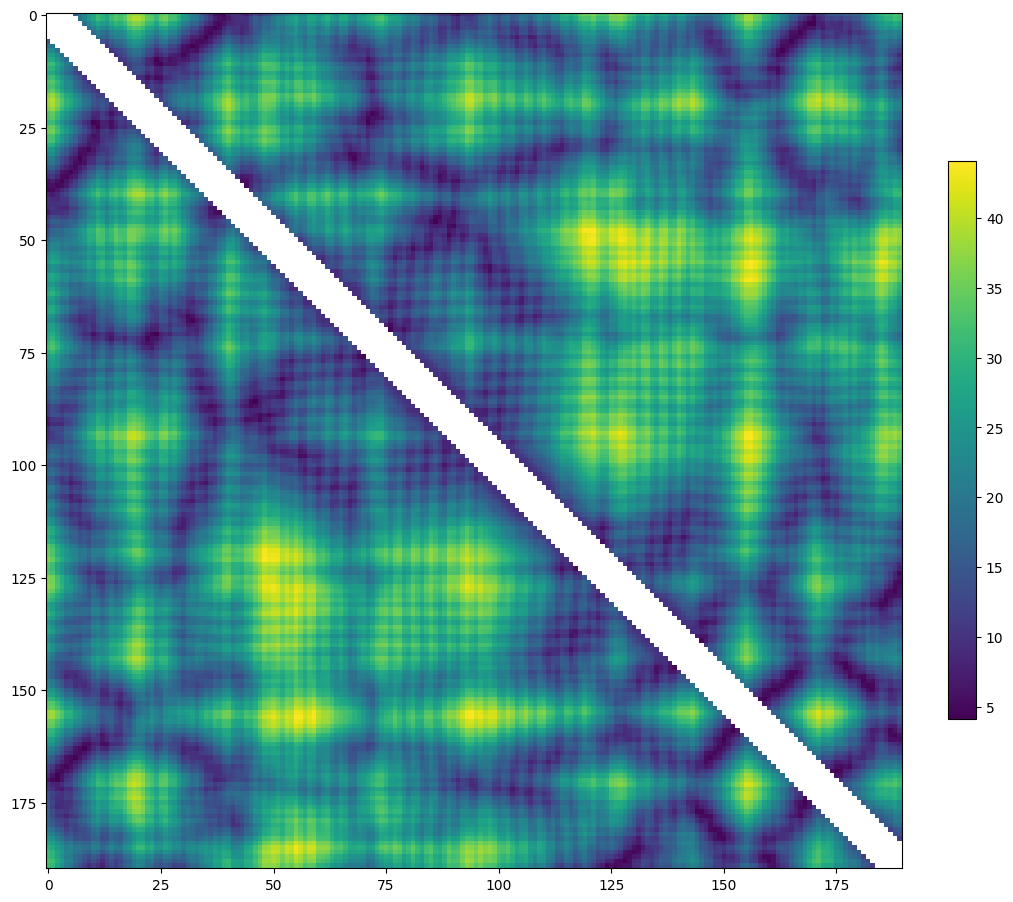

In [ ]:
# Plot distance matrix

# Alter the color map to highlight nan values (the diagonal)
current_cmap = copy.copy(matplotlib.cm.get_cmap())
current_cmap.set_bad(color='white')

fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(dist_matrix)
fig.colorbar(im, fraction=0.03, pad=0.05)
plt.savefig(path + '/figures/ca_distances_{}.png'.format(pdb_id), dpi=300, bbox_inches='tight')

# Contact map

In [ ]:
# Calculate the contact map based on a distace threshold 8 Angstrom
# Create a mask of the distance matrix based on a filter and cast to float
contact_map = (dist_matrix[:] < 4.5).astype(float)
contact_map

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

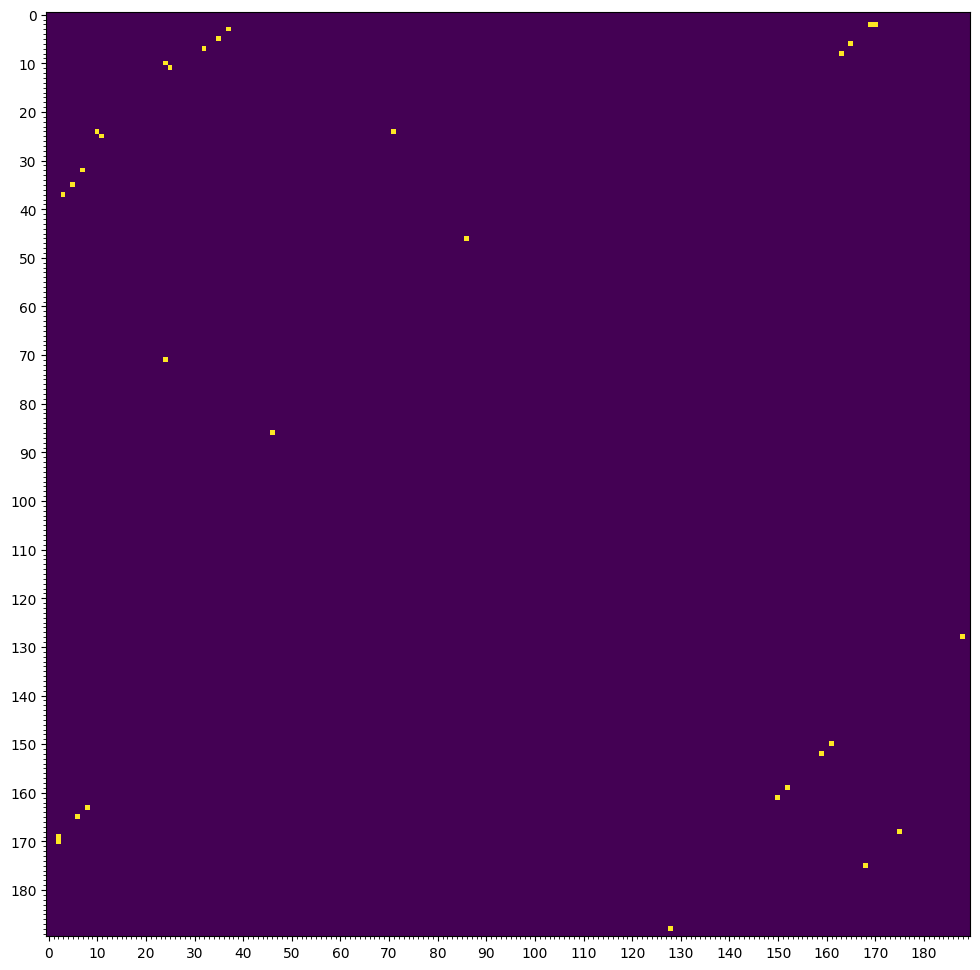

In [ ]:
# Plot contact map
fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(contact_map)

# Set ticks
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.xaxis.set_minor_locator(AutoMinorLocator(10))
ax.yaxis.set_major_locator(MultipleLocator(10))
ax.yaxis.set_minor_locator(AutoMinorLocator(10))

plt.savefig(path + '/figures/ca_contacts_{}.png'.format(pdb_id), dpi=300, bbox_inches='tight')

# Contact map (NeighborSearch)

In [ ]:
# Calculate the contact map using the NeighborSearch module (fast)
# https://biopython.org/docs/1.75/api/Bio.PDB.NeighborSearch.html

# Input
pdb_id = '1vy4'

# Fetch a PDB file to the current dir
pdbl = PDBList()
pdbl.retrieve_pdb_file(pdb_id, pdir=path + "/pdb", file_format='mmCif')
structure = MMCIFParser(QUIET=True).get_structure(pdb_id, path + "/pdb/{}.cif".format(pdb_id))

# Select chain A of first model (0) and exclude hetero and water groups
selected_residues = [residue for residue in structure[0]['AB'] if residue.id[0] == " "]

# Calculate contacts
ns = NeighborSearch([atom for residue in selected_residues for atom in residue.get_atoms()])

# Init a empty matrix
contact_map_nb = np.zeros((len(selected_residues), len(selected_residues)))

# "search_all" returns the list of atoms in contact based on a distance cutoff
# level="R" returns pairs of residues instead of atoms
for residue1, residue2 in ns.search_all(4.5, level="R"):
  # Sequence separation >= 6
  if abs(residue1.id[1] - residue2.id[1]) >= 6:
    contact_map_nb[selected_residues.index(residue1), selected_residues.index(residue2)] = 1
    # Add also the other part of the matrix
    contact_map_nb[selected_residues.index(residue2), selected_residues.index(residue1)] = 1
contact_map_nb

Structure exists: 'drive/MyDrive/Teaching/StructuralBioinformatics (Computer Science)/practicum/data/pdb/1vy4.cif' 


array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

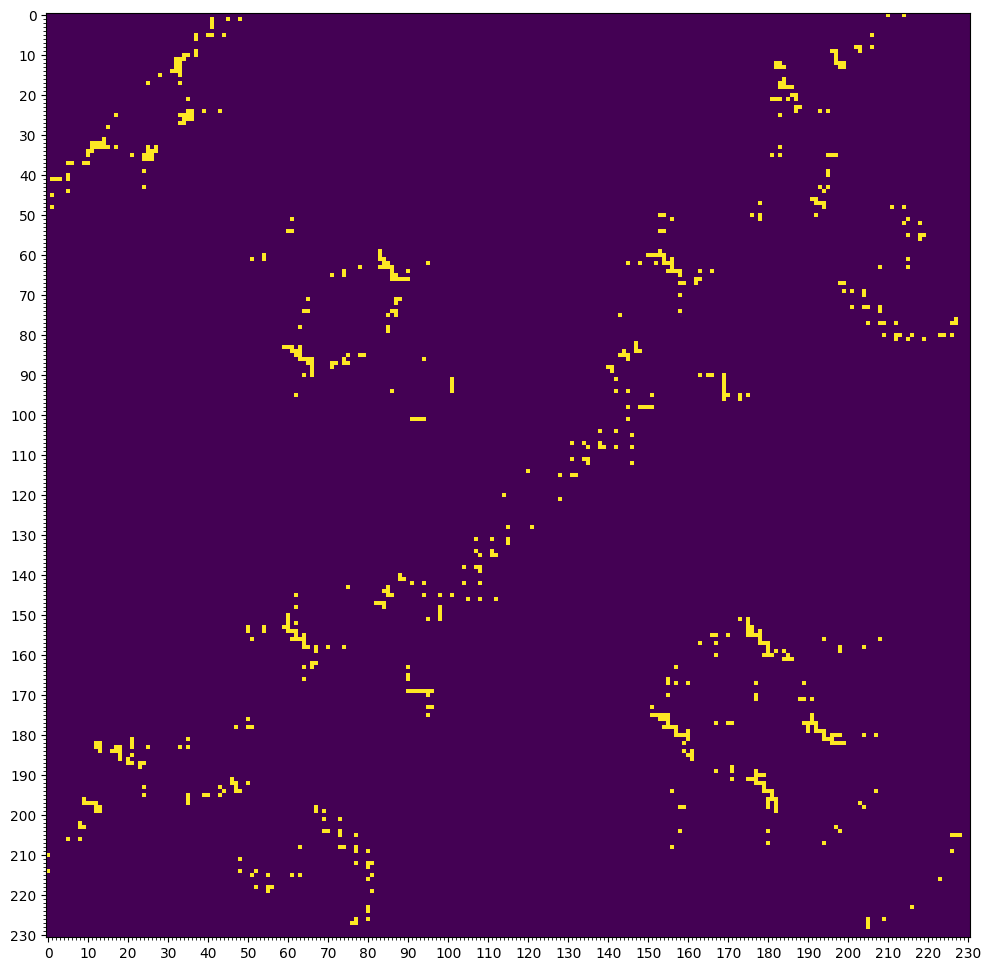

In [ ]:
# Plot contact map
fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(contact_map_nb)

# Set ticks
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.xaxis.set_minor_locator(AutoMinorLocator(10))
ax.yaxis.set_major_locator(MultipleLocator(10))
ax.yaxis.set_minor_locator(AutoMinorLocator(10))

plt.savefig(path + '/figures/all_contacts_{}.png'.format(pdb_id), dpi=300, bbox_inches='tight')

# Compare contact maps

In [ ]:
pdbl = PDBList()

# Input
pdb_ids = ['1ucd', '1ioo']

pdbl.download_pdb_files(pdb_ids, pdir=path + "/pdb", file_format='pdb')

structure = PDBParser(QUIET=True).get_structure(pdb_id, path + "/pdb/pdb{}.ent".format(pdb_ids[0]))
selected_residues = [residue for residue in structure[0]['A'] if residue.id[0] == " "]
dist_matrix = get_distance_matrix(selected_residues, seq_sep=0)

structure = PDBParser(QUIET=True).get_structure(pdb_id, path +"/pdb/pdb{}.ent".format(pdb_ids[1]))
selected_residues = [residue for residue in structure[0]['A'] if residue.id[0] == " "]
dist_matrix2 = get_distance_matrix(selected_residues, seq_sep=0)

Structure exists: 'drive/MyDrive/Teaching/StructuralBioinformatics (Computer Science)/practicum/data/pdb/pdb1ucd.ent' 
Structure exists: 'drive/MyDrive/Teaching/StructuralBioinformatics (Computer Science)/practicum/data/pdb/pdb1ioo.ent' 


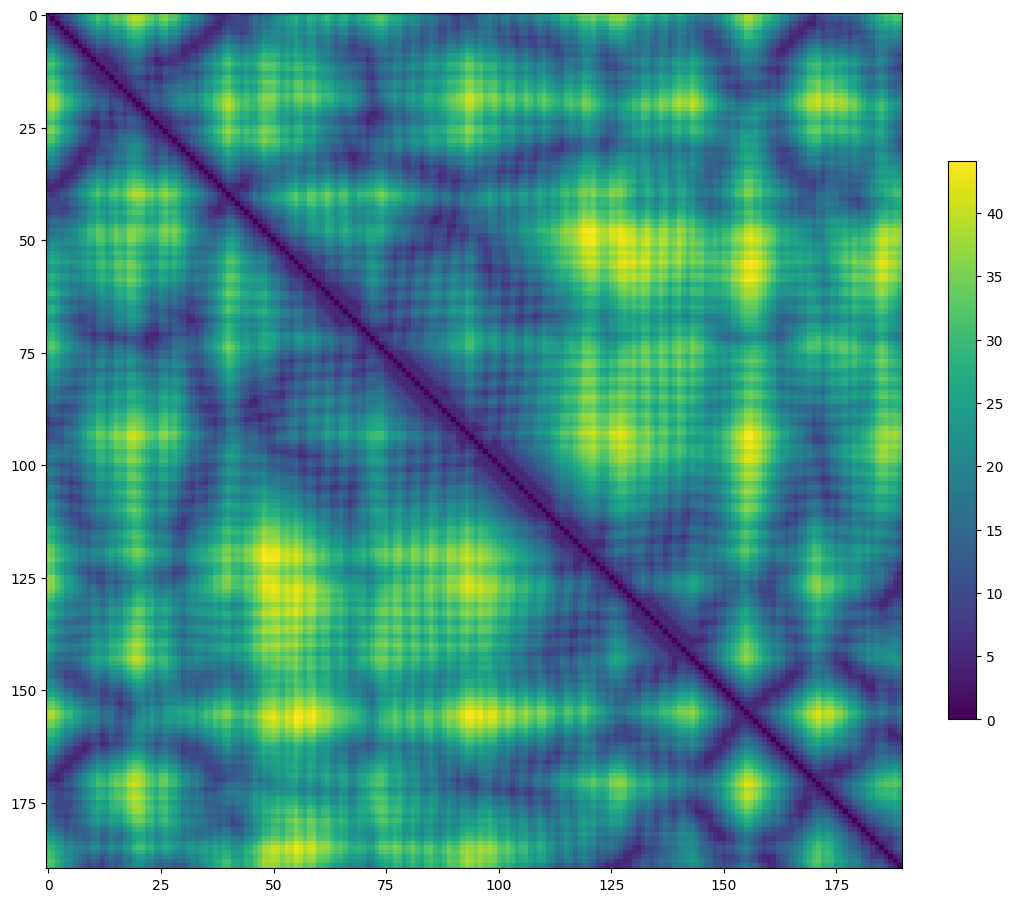

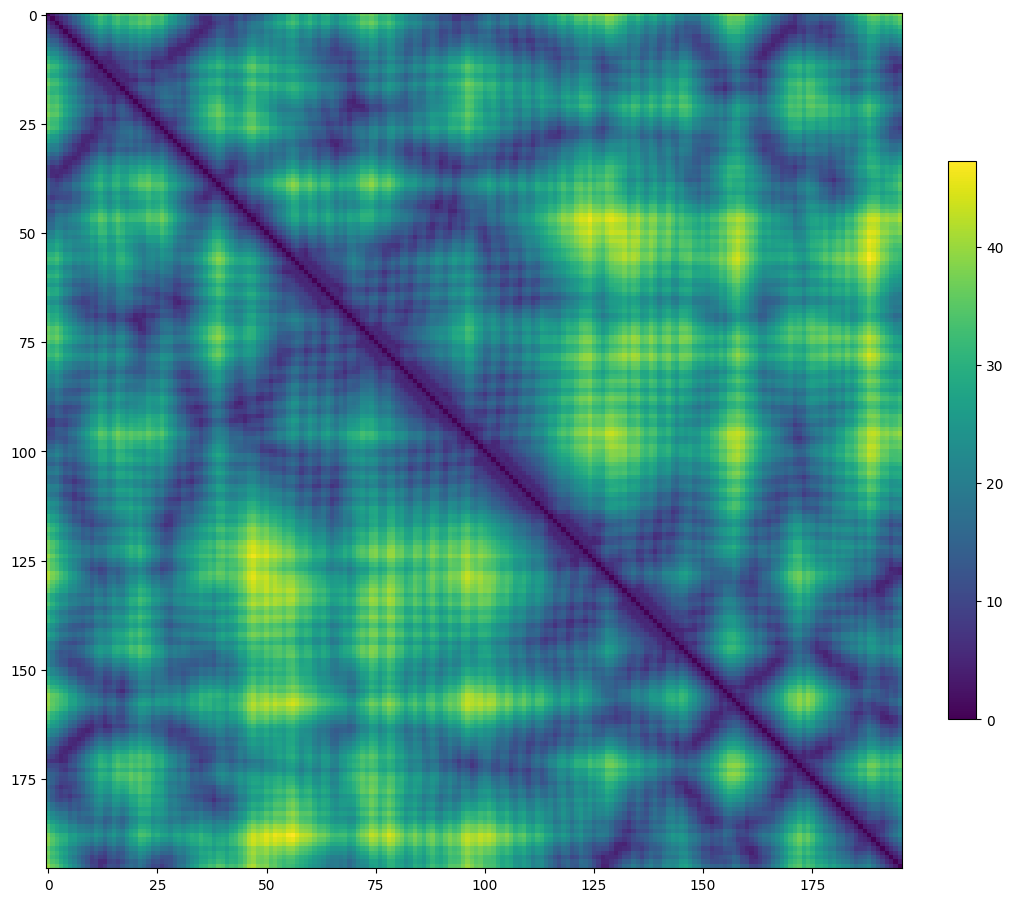

In [ ]:
# Plot distance matrix
fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(dist_matrix)
fig.colorbar(im, fraction=0.03, pad=0.05)

fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(dist_matrix2)
fig.colorbar(im, fraction=0.03, pad=0.05)

In [ ]:
# Align contact maps / distance matrices (cross-correlation)
# https://stackoverflow.com/questions/59651335/aligning-two-binary-matrices-for-maximum-overlap

# Replace NaN inplace (not necessary if sequence separation threshold is set to 0)
np.nan_to_num(dist_matrix, copy=False, nan=0.0)
np.nan_to_num(dist_matrix2, copy=False, nan=0.0)

# Contact maps
contact_matrix = (dist_matrix[:] < 8).astype(float)
contact_matrix2 = (dist_matrix2[:] < 8).astype(float)

# Cross correlation
# Check distance matrix has diagonals, otherwise cross correlation fail
#corr = scipy.signal.correlate2d(contact_matrix2, contact_matrix, mode="same")

# Convolution (it flips the second matrix, not a problem if the matrix is symmetric)

# Convolve entyre matrix
#corr = scipy.signal.convolve2d(contact_matrix2, contact_matrix)

# Convolve a submatrix
corr = scipy.signal.convolve2d(contact_matrix2, contact_matrix[0:10, 0:10])

# print(corr)

# Find which is the maximum correlation
# and which is the point where the two matrices reach this value
y, x = np.unravel_index(np.argmax(corr), corr.shape)
print(corr.max())
print(x, y)

46.0
13 13


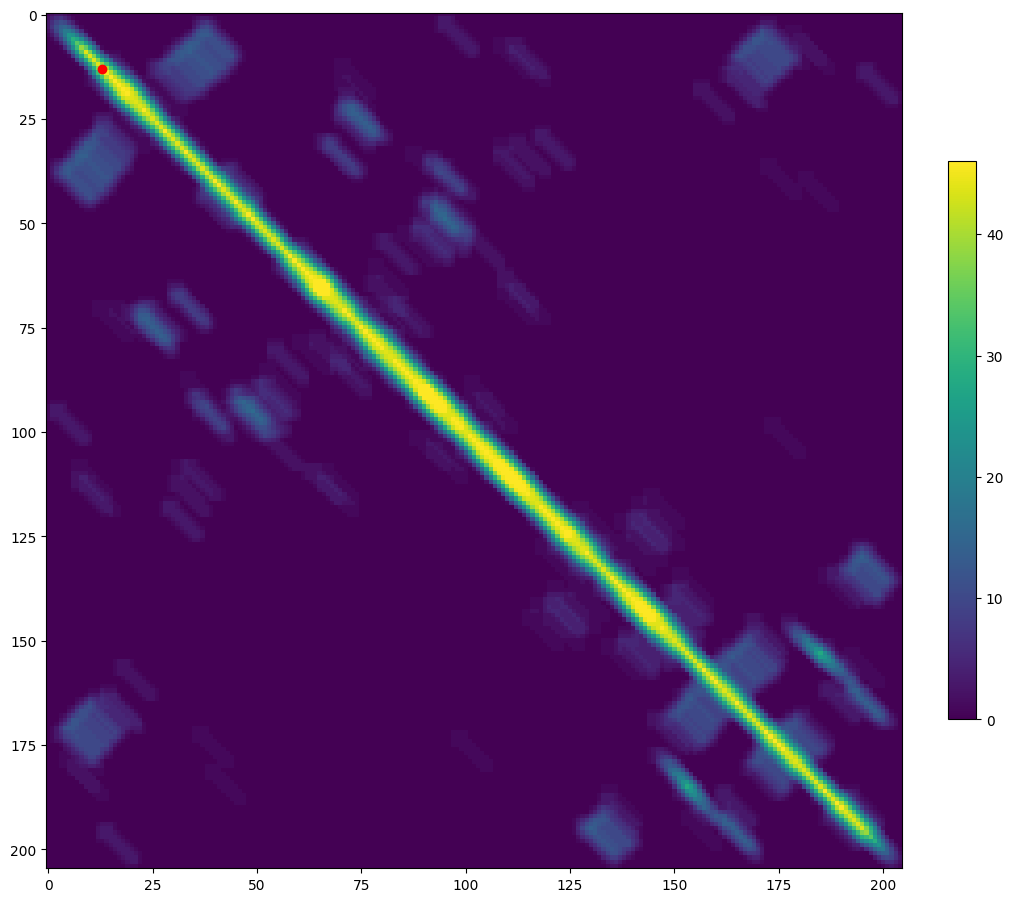

In [ ]:
# Plot cross-correlation
fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(corr)
ax.scatter([x], [y], color='red')
fig.colorbar(im, fraction=0.03, pad=0.05)

137.0
90 95


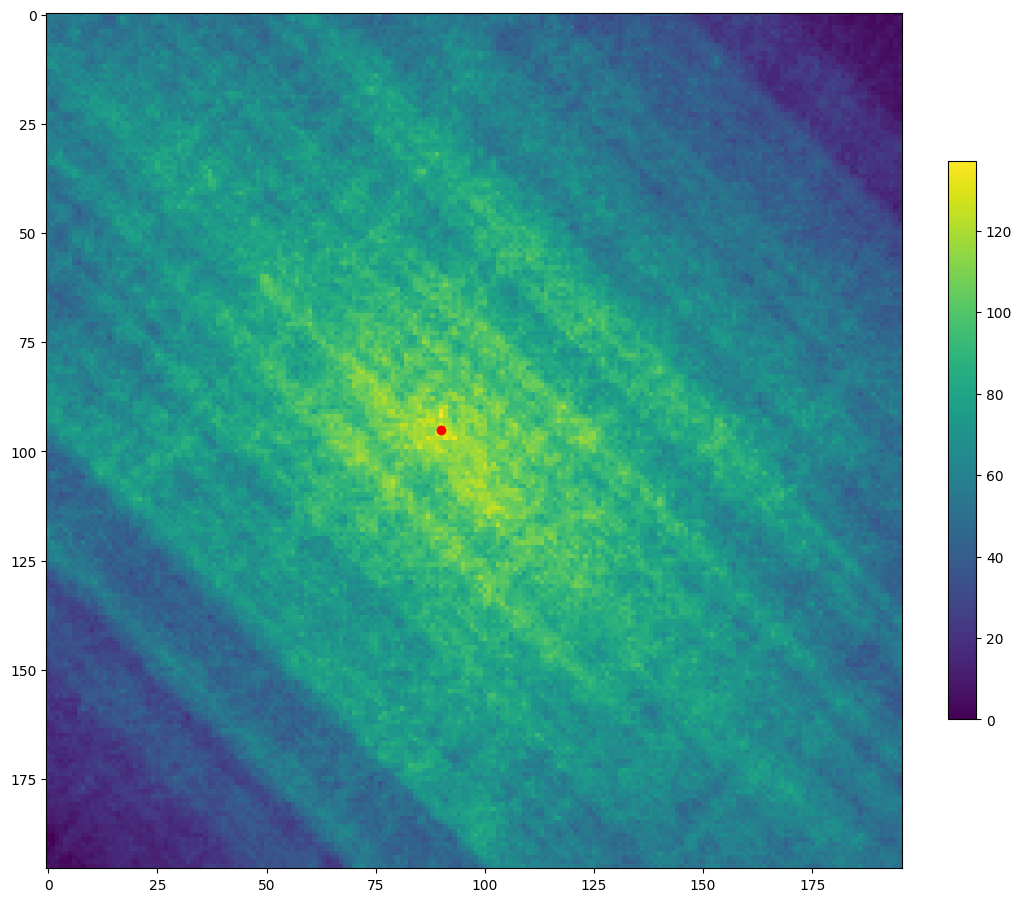

In [ ]:
# Plot cross-correlation with one random matrix

# Randomize the first matrix
random_matrix = np.copy(contact_matrix) #first copy the contact map in a new variable
for row in random_matrix:
  np.random.shuffle(row)

corr_random = scipy.signal.correlate2d(contact_matrix2, random_matrix, mode="same")  # cross correlation random
y, x = np.unravel_index(np.argmax(corr_random), corr_random.shape)  # find the match
print(corr_random.max())
print(x, y)

fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(corr_random)
ax.scatter([x], [y], color='red')
fig.colorbar(im, fraction=0.03, pad=0.05)

In [ ]:
# Slide a small matrix onto the other and calaculate convolution
results = []
w_size = 20
for i in range(0, contact_matrix2.shape[0]-w_size, 4):
    for j in range(0, contact_matrix2.shape[1]-w_size, 4):
        corr = scipy.signal.convolve2d(np.triu(contact_matrix2[i:i+w_size, j:j+w_size]), np.triu(contact_matrix, 0), mode='same')
        y, x = np.unravel_index(np.argmax(corr), corr.shape)
        results.append([i, j, x, y, corr.max()])
sorted(results, key=lambda x: x[-1], reverse=True)[:10]

[[88, 84, np.int64(13), np.int64(8), np.float64(86.0)],
 [92, 88, np.int64(9), np.int64(4), np.float64(86.0)],
 [76, 72, np.int64(6), np.int64(1), np.float64(85.0)],
 [84, 80, np.int64(13), np.int64(8), np.float64(85.0)],
 [96, 92, np.int64(5), np.int64(0), np.float64(85.0)],
 [80, 76, np.int64(6), np.int64(1), np.float64(84.0)],
 [104, 100, np.int64(10), np.int64(5), np.float64(84.0)],
 [72, 68, np.int64(10), np.int64(5), np.float64(83.0)],
 [80, 80, np.int64(4), np.int64(0), np.float64(83.0)],
 [100, 96, np.int64(5), np.int64(0), np.float64(83.0)]]

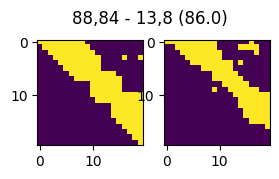

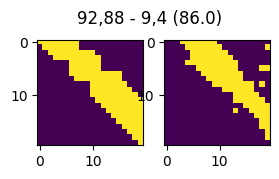

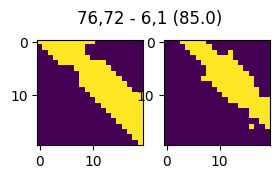

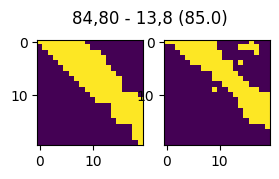

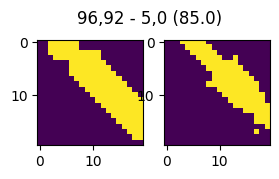

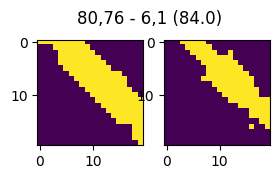

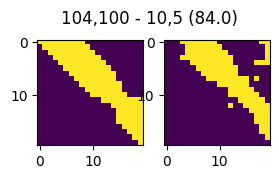

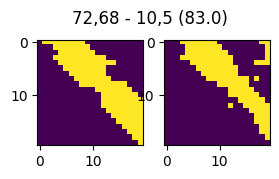

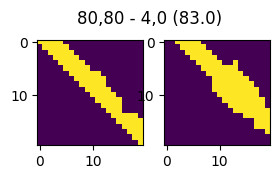

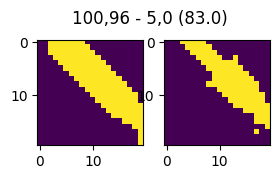

In [ ]:
for i, j, x, y, corr in sorted(results, key=lambda x: x[-1], reverse=True)[:10]:
  fig, axes = plt.subplots(ncols=2, nrows=1, figsize=(3, 3))
  axes[0].imshow(np.triu(contact_matrix2[i:i+w_size, j:j+w_size]))
  axes[1].imshow(np.triu(contact_matrix[x:x+w_size, y:y+w_size]))

  fig.suptitle("{},{} - {},{} ({})".format(i,j,x,y, corr))
  fig.subplots_adjust(top=1.3) # move the plot closer to the title
